# Siamese network for curl leaves (MobileNetV2)
Tells if two pear leaf images are both curl or not.

**1. Imports**

In [1]:
import os
import logging
import warnings
import numpy as np
from matplotlib import pyplot as plt
%matplotlib inline

In [2]:
# hide the deprecation warnings (tensorflow resets the log level in jupyter)
logging.getLogger('tensorflow').addFilter(lambda record: record.levelno >= logging.ERROR)
warnings.filterwarnings('ignore')

import tensorflow as tf
from keras.models import Model
from keras.layers import Layer, Input, Flatten, Dense
from keras.metrics import BinaryAccuracy, Precision, Recall, Mean

tf.random.set_seed(42)

**2. Paths**

Run `split_data.py` once before this so `King_Saud/Test` exists.

In [3]:
# On Colab mount Drive and use the Drive folder instead
# from google.colab import drive
# drive.mount('/gdrive')
# DATA_DIR = '/gdrive/My Drive/King_Saud'
DATA_DIR = 'King_Saud'
CLASS = 'curl'

TRAIN_DIR = os.path.join(DATA_DIR, 'Train', CLASS)
TEST_DIR = os.path.join(DATA_DIR, 'Test', CLASS)

**3. Load and preprocess images**

In [4]:
def preprocess(file_path):
    byte_img = tf.io.read_file(file_path)
    img = tf.io.decode_jpeg(byte_img, channels=3)
    img = tf.image.resize(img, (100, 100))
    # MobileNetV2 wants pixels between -1 and 1
    img = img / 127.5 - 1
    return img


def preprocess_twin(input_img, validation_img, label):
    return (preprocess(input_img), preprocess(validation_img), label)

In [5]:
# anchor + positive = same class (label 1), anchor + negative = other class (label 0)
def make_pairs(folder):
    anchor = tf.data.Dataset.list_files(os.path.join(folder, 'anchor', '*.jpg'), seed=1)
    positive = tf.data.Dataset.list_files(os.path.join(folder, 'positive', '*.jpg'), seed=2)
    negative = tf.data.Dataset.list_files(os.path.join(folder, 'negative', '*.jpg'), seed=3)

    positives = tf.data.Dataset.zip((anchor, positive, tf.data.Dataset.from_tensor_slices(tf.ones(len(anchor)))))
    negatives = tf.data.Dataset.zip((anchor, negative, tf.data.Dataset.from_tensor_slices(tf.zeros(len(anchor)))))
    data = positives.concatenate(negatives)
    return data.map(preprocess_twin).cache()

In [6]:
# train and test come from different leaves (see split_data.py)
train_data = make_pairs(TRAIN_DIR)
test_data = make_pairs(TEST_DIR)
print('train pairs:', len(train_data))
print('test pairs:', len(test_data))

train pairs: 381
test pairs: 94


In [7]:
train_data = train_data.shuffle(buffer_size=1000)
train_data = train_data.batch(16)
train_data = train_data.prefetch(8)

test_data = test_data.batch(16)
test_data = test_data.prefetch(8)

**4. Model**

In [8]:
class L1Dist(Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    # distance between the two embeddings
    def call(self, input_embedding, validation_embedding):
        return tf.math.abs(input_embedding - validation_embedding)

In [9]:
from keras.applications import MobileNetV2

def make_siamese_model():
    input_image = Input(name='input_img', shape=(100, 100, 3))
    validation_image = Input(name='validation_img', shape=(100, 100, 3))

    # pretrained MobileNetV2, kept frozen
    base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(100, 100, 3))
    base_model.trainable = False

    input_features = base_model(input_image)
    validation_features = base_model(validation_image)

    distances = L1Dist(name='distance')(input_features, validation_features)
    f1 = Flatten()(distances)
    classifier = Dense(1, activation='sigmoid')(f1)

    return Model(inputs=[input_image, validation_image], outputs=classifier, name='SiameseNetwork')

In [10]:
siamese_model = make_siamese_model()
siamese_model.summary()

Model: "SiameseNetwork"


__________________________________________________________________________________________________


 Layer (type)                Output Shape                 Param #   Connected to                  


 input_img (InputLayer)      [(None, 100, 100, 3)]        0         []                            


 validation_img (InputLayer  [(None, 100, 100, 3)]        0         []                            


 )                                                                                                


... (6 outputs left out)

Total params: 2278465 (8.69 MB)


Trainable params: 20481 (80.00 KB)


Non-trainable params: 2257984 (8.61 MB)


__________________________________________________________________________________________________


**5. Training**

In [11]:
binary_cross_loss = tf.losses.BinaryCrossentropy()
opt = tf.keras.optimizers.Adam(1e-4)

checkpoint_dir = './training_checkpoints/MobileNetV2_Curl'
checkpoint_prefix = os.path.join(checkpoint_dir, 'ckpt')
checkpoint = tf.train.Checkpoint(opt=opt, siamese_model=siamese_model)

In [12]:
@tf.function
def train_step(batch):
    with tf.GradientTape() as tape:
        # anchor and pos/neg image
        X = batch[:2]
        y = batch[2]

        yhat = siamese_model(X, training=True)
        loss = binary_cross_loss(y, yhat)

    grad = tape.gradient(loss, siamese_model.trainable_variables)
    opt.apply_gradients(zip(grad, siamese_model.trainable_variables))
    return loss, yhat

In [13]:
def train(data, EPOCHS):
    for epoch in range(1, EPOCHS+1):
        mean_loss = Mean()
        acc = BinaryAccuracy()

        for batch in data:
            loss, yhat = train_step(batch)
            mean_loss.update_state(loss)
            acc.update_state(batch[2], yhat)

        print('Epoch {}/{}  loss: {:.4f}  accuracy: {:.4f}'.format(
            epoch, EPOCHS, mean_loss.result(), acc.result()))

        if epoch % 10 == 0:
            checkpoint.save(file_prefix=checkpoint_prefix)

In [14]:
EPOCHS = 20
train(train_data, EPOCHS)

Epoch 1/20  loss: 0.8601  accuracy: 0.5906


Epoch 2/20  loss: 0.4044  accuracy: 0.8268


Epoch 3/20  loss: 0.2602  accuracy: 0.9003


Epoch 4/20  loss: 0.1743  accuracy: 0.9475


Epoch 5/20  loss: 0.1373  accuracy: 0.9554


Epoch 6/20  loss: 0.1016  accuracy: 0.9816


... (10 outputs left out)

Epoch 17/20  loss: 0.0198  accuracy: 1.0000


Epoch 18/20  loss: 0.0181  accuracy: 1.0000


Epoch 19/20  loss: 0.0169  accuracy: 1.0000


Epoch 20/20  loss: 0.0154  accuracy: 1.0000


**6. Evaluate on the test leaves**

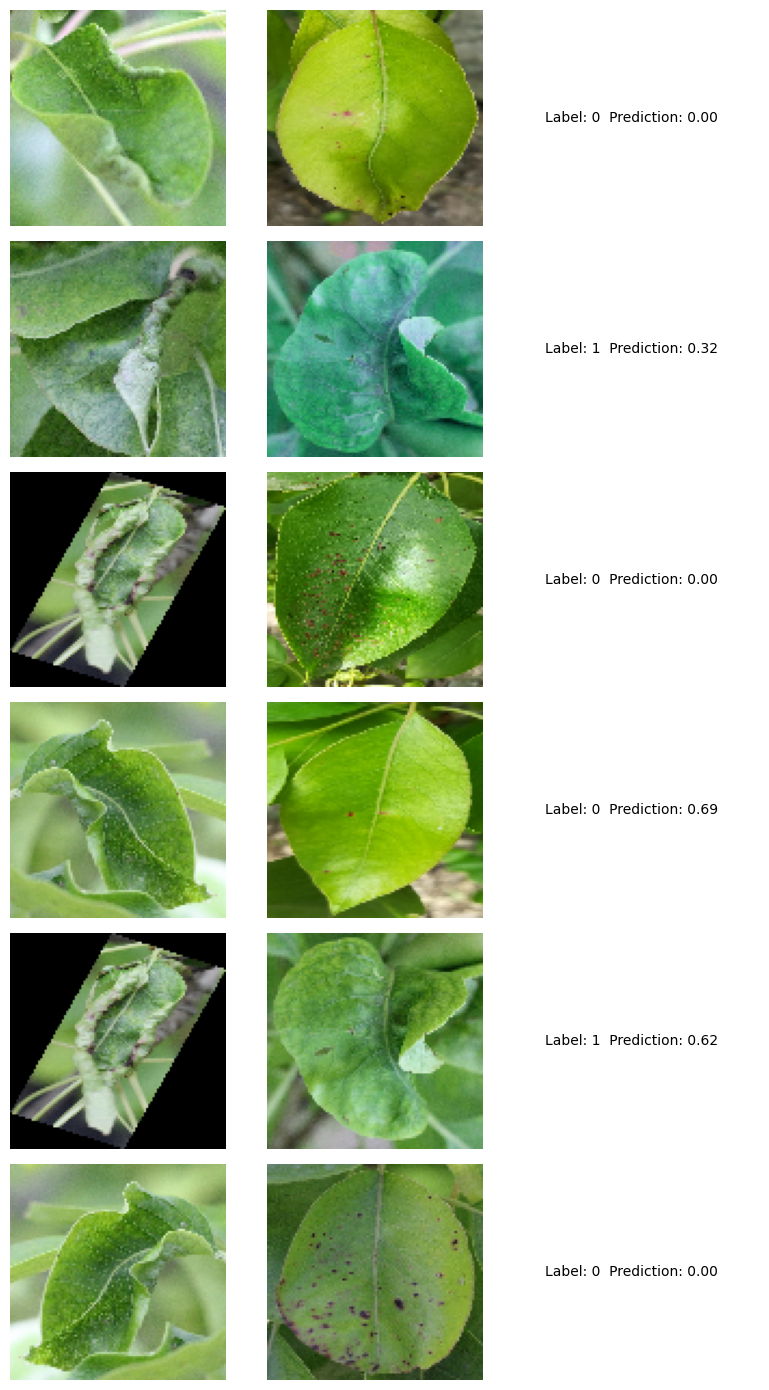

In [15]:
def show(img):
    return (img + 1) / 2

# 6 random test pairs
sample = test_data.unbatch().shuffle(500, seed=0).batch(6)
test_input, test_val, y_true = sample.as_numpy_iterator().next()
y_hat = siamese_model.predict([test_input, test_val], verbose=0)

fig, axes = plt.subplots(6, 3, figsize=(8, 14))
for i in range(6):
    axes[i, 0].imshow(show(test_input[i]))
    axes[i, 1].imshow(show(test_val[i]))
    text = 'Label: {:.0f}  Prediction: {:.2f}'.format(y_true[i], y_hat[i][0])
    axes[i, 2].text(0.5, 0.5, text, va='center', ha='center')
    for ax in axes[i]:
        ax.axis('off')
plt.tight_layout()
plt.show()

In [16]:
acc = BinaryAccuracy()
precision = Precision()
recall = Recall()

for test_input, test_val, y_true in test_data.as_numpy_iterator():
    y_hat = siamese_model.predict([test_input, test_val], verbose=0)
    acc.update_state(y_true, y_hat)
    precision.update_state(y_true, y_hat)
    recall.update_state(y_true, y_hat)

p = precision.result().numpy()
r = recall.result().numpy()
f1 = 2 * p * r / (p + r) if p + r > 0 else 0.0

print('Test accuracy:  {:.4f}'.format(acc.result().numpy()))
print('Test precision: {:.4f}'.format(p))
print('Test recall:    {:.4f}'.format(r))
print('Test F1 score:  {:.4f}'.format(f1))

Test accuracy:  0.9468
Test precision: 0.9375
Test recall:    0.9574
Test F1 score:  0.9474


**7. Save model**

In [17]:
os.makedirs('models', exist_ok=True)
siamese_model.save('models/MobileNetV2_Curl.h5')

In [18]:
# check the saved file loads back
model = tf.keras.models.load_model('models/MobileNetV2_Curl.h5',
                                   custom_objects={'L1Dist': L1Dist}, compile=False)
model.predict([test_input[:4], test_val[:4]], verbose=0)

array([[0.0001435 ],
       [0.00145974],
       [0.00696106],
       [0.0148033 ]], dtype=float32)